# 04 · Frente de onda y límite de difracción

Extra 5. El trazado de rayos dice dónde cruza cada rayo; la óptica ondulatoria dice si eso importa. Si todos los rayos llegaran a la imagen con el mismo **camino óptico** (principio de Fermat), las ondas llegarían en fase y la imagen de un punto sería el patrón de difracción de la apertura (disco de Airy). La diferencia de camino de cada rayo es el **error del frente de onda** $W$; con él se decide si la lente está limitada por la difracción o por la aberración.

**Supuestos.** Las longitudes del proyecto se leen como milímetros y la luz es verde, $\lambda = 550$ nm. Objeto en el eje, en $y = -30$ (el del ejemplo resuelto). Difracción escalar y pupila circular iluminada de forma uniforme.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from lentes import lente_biconvexa
from lentes.aberraciones import y_paraxial
from lentes.difraccion import (LAMBDA_VERDE, apertura_cruce, apertura_limite, apertura_numerica, haz,
                               mejor_foco_onda, psf, radio_airy, radio_rms_geometrico, strehl, strehl_marechal)
from lentes.estilo import RAMPA_AZUL, TINTA_2, aplicar_estilo
from lentes.seidel import k_que_anula, suma_seidel

aplicar_estilo()
lam, y_obj = LAMBDA_VERDE, -30.0
k_cero = k_que_anula(lente_biconvexa(10, 10, 2.0, 1.5, 0.0, 0.0), y_obj)
lentes = {"esfera": lente_biconvexa(10, 10, 2.0, 1.5, 0.0, 0.0),
          "parábola": lente_biconvexa(10, 10, 2.0, 1.5, -1.0, -1.0),
          "asférica": lente_biconvexa(10, 10, 2.0, 1.5, k_cero, k_cero)}
haces = {nombre: haz(lente, y_obj) for nombre, lente in lentes.items()}
print(f"Cónica que anula el tercer orden: k = {k_cero:.4f}")

Cónica que anula el tercer orden: k = -2.3294


## 1. Camino óptico y error del frente de onda

Para cada rayo se suma $n \cdot \ell$ a lo largo de su recorrido: aire hasta la cara $g$, vidrio hasta la cara $f$ y aire hasta una **esfera de referencia** centrada en el punto imagen que pasa por el vértice de salida. Si la lente fuera perfecta, esa esfera sería un frente de onda y todos los caminos serían iguales. Con la convención de los libros,

$$W(h) = \mathrm{OPL}(\text{rayo axial}) - \mathrm{OPL}(\text{rayo que entra a la altura } h).$$

En tercer orden la teoría de Seidel predice $W = \tfrac{S_I}{8}\,h^4$ con la referencia en la imagen paraxial. Es un tercer camino independiente para la misma aberración: el primero fue dónde cruzan los rayos (notebook 02) y el segundo la suma de Seidel.

In [2]:
for nombre in ("esfera", "parábola"):
    lente, hz = lentes[nombre], haces[nombre]
    hs = np.linspace(0.02, 0.3, 15)
    W = hz.frente_de_onda(hs, y_paraxial(lente, y_obj))
    c4 = np.linalg.lstsq(np.vstack([hs**2, hs**4, hs**6, hs**8]).T, W, rcond=None)[0][1]
    print(f"{nombre:9s}  W040 por Fermat = {c4:.6e} mm   S_I/8 de Seidel = {suma_seidel(lente, y_obj) / 8:.6e} mm"
          f"   cociente = {c4 / (suma_seidel(lente, y_obj) / 8):.7f}")

esfera     W040 por Fermat = 2.794958e-04 mm   S_I/8 de Seidel = 2.794956e-04 mm   cociente = 1.0000005
parábola   W040 por Fermat = 1.595098e-04 mm   S_I/8 de Seidel = 1.595097e-04 mm   cociente = 1.0000008


## 2. El mejor foco para las ondas está a mitad de camino

Moverse a lo largo del eje agrega un término de desenfoque $W_{020}\rho^2$. Con $W = W_{040}\rho^4 + W_{020}\rho^2$, el menor $W_\text{rms}$ se logra con $W_{020} = -W_{040}$: a **mitad de camino** entre el foco paraxial y el marginal, y ese RMS es **la cuarta parte** del que hay en el foco paraxial ($\sqrt{1/180}$ frente a $\sqrt{4/45}$). El notebook 02 mostró que la mancha geométrica más chica está a 2/3 y el círculo de mínima confusión a 3/4: el "mejor foco" depende de qué se quiera medir.

In [3]:
hz = haces["parábola"]
for h_max in (0.3, 2.0):
    f = mejor_foco_onda(hz, h_max)
    print(f"h_max = {h_max}:  mejor foco en la fracción {f.fraccion(f.y_ref):.4f} del camino paraxial → marginal; "
          f"W_rms = {f.rms / lam:.4f} λ (en el foco paraxial: {f.rms_paraxial / lam:.4f} λ, cociente {f.rms / f.rms_paraxial:.4f})")

h_max = 0.3:  mejor foco en la fracción 0.4999 del camino paraxial → marginal; W_rms = 0.0002 λ (en el foco paraxial: 0.0007 λ, cociente 0.2501)
h_max = 2.0:  mejor foco en la fracción 0.4957 del camino paraxial → marginal; W_rms = 0.3520 λ (en el foco paraxial: 1.3710 λ, cociente 0.2568)


## 3. ¿Hasta qué apertura manda la difracción?

**Criterio de Maréchal:** una lente está limitada por la difracción si $W_\text{rms} \le \lambda/14$, lo que equivale a un **Strehl** (pico de la imagen de un punto dividido por el de una lente perfecta) de 0.8. El Strehl exacto se calcula con la integral de difracción de la pupila circular,

$$S = \left|\int_0^1 2\rho\, e^{\,i\,2\pi W(\rho)/\lambda}\, d\rho\right|^2,$$

y la aproximación de Maréchal es $S \approx e^{-(2\pi W_\text{rms}/\lambda)^2}$.

La otra forma de verlo: la mancha geométrica crece como $h^3$ y el disco de Airy, $0.61\,\lambda/\mathrm{NA}$, se achica como $1/h$. Donde se cruzan cambia quién manda.

In [4]:
print(f"{'lente':9s} {'h* (mm)':>8s} {'D* (mm)':>8s} {'f/#':>6s} {'Airy (μm)':>10s} {'cruce (mm)':>11s}"
      f" {'W_rms h=4 (λ)':>14s} {'Strehl h=4':>11s}")
for nombre, hz in haces.items():
    h_lim, h_c = apertura_limite(hz), apertura_cruce(hz)
    na = apertura_numerica(hz, h_lim)
    f4 = mejor_foco_onda(hz, 4.0)
    print(f"{nombre:9s} {h_lim:8.2f} {2 * h_lim:8.2f} {1 / (2 * na):6.1f} {radio_airy(hz, h_lim) * 1e3:10.2f}"
          f" {h_c:11.2f} {f4.rms / lam:14.2f} {strehl(hz, 4.0, f4.y_ref):11.3f}")

lente      h* (mm)  D* (mm)    f/#  Airy (μm)  cruce (mm)  W_rms h=4 (λ)  Strehl h=4
esfera        1.17     2.34    6.5       4.38        1.15          11.31       0.003
parábola      1.35     2.69    5.7       3.83        1.33           5.89       0.006
asférica      4.09     8.19    2.0       1.35        3.92           0.06       0.852


In [5]:
hz = haces["parábola"]
for h_max in (0.8, 1.0, 1.2, apertura_limite(hz)):
    f = mejor_foco_onda(hz, h_max)
    print(f"h_max = {h_max:.3f}:  Strehl exacto = {strehl(hz, h_max, f.y_ref):.4f}   Maréchal = {strehl_marechal(f.rms / lam):.4f}")

h_max = 0.800:  Strehl exacto = 0.9969   Maréchal = 0.9969
h_max = 1.000:  Strehl exacto = 0.9815   Maréchal = 0.9816
h_max = 1.200:  Strehl exacto = 0.9224   Maréchal = 0.9228
h_max = 1.346:  Strehl exacto = 0.8152   Maréchal = 0.8176


## 4. La imagen de un punto

La intensidad a la distancia $r$ del eje, en el mejor foco, es la integral de difracción de la pupila con la fase $2\pi W/\lambda$ (cada anillo de rayos aporta con $J_0(k\,r\,\sin\theta)$). Se normaliza al pico de una lente perfecta de la misma apertura, así que en $r = 0$ vale el Strehl. Con poca apertura se ve el patrón de Airy; con mucha, la aberración se come el pico y reparte la luz en anillos.

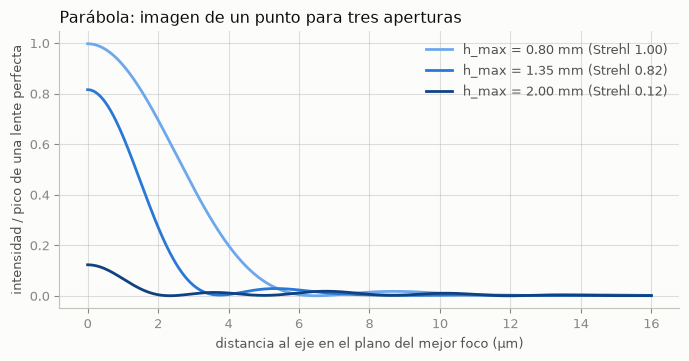

In [6]:
r = np.linspace(0, 16, 800)  # μm
fig, ax = plt.subplots(figsize=(8, 3.6))
for h_max, color in ((0.8, RAMPA_AZUL[1]), (apertura_limite(hz), RAMPA_AZUL[4]), (2.0, RAMPA_AZUL[8])):  # más oscuro = más apertura
    f = mejor_foco_onda(hz, h_max)
    ax.plot(r, psf(hz, h_max, f.y_ref, r * 1e-3), color=color, lw=2,
            label=f"h_max = {h_max:.2f} mm (Strehl {strehl(hz, h_max, f.y_ref):.2f})")
ax.set_xlabel("distancia al eje en el plano del mejor foco (μm)")
ax.set_ylabel("intensidad / pico de una lente perfecta")
ax.set_title("Parábola: imagen de un punto para tres aperturas", loc="left")
ax.legend(frameon=False, labelcolor=TINTA_2)
ax.grid(True, alpha=0.4)
plt.show()

## Qué muestra

- El camino óptico (Fermat), la suma de Seidel y el cruce de los rayos dan la misma aberración de tercer orden: tres métodos independientes que se validan entre sí (`tests/test_difraccion.py`).
- Con toda la lente abierta, la parábola tiene un error de frente de onda de unas 6 longitudes de onda y la esfera de 11: la imagen la limita la aberración, no la difracción.
- Cerrando la apertura a unos 2.3 mm de diámetro (esfera) o 2.7 mm (parábola) la lente pasa a estar limitada por la difracción. Los dos criterios (Maréchal y mancha = Airy) dan casi la misma apertura.
- La asférica que anula el tercer orden queda limitada por difracción casi con toda la lente abierta (unos 8 mm de diámetro, f/2): unas 12 veces más luz que la esfera con la misma nitidez. Por eso las cámaras de los celulares y los telescopios usan superficies asféricas.
- Une el trazado de rayos con la difracción del curso: el disco de Airy es la versión circular del patrón de una rendija.

Límites: difracción escalar, luz de un solo color y pupila uniforme; el resultado depende de leer las longitudes como milímetros (una lente 10 veces más grande tendría 10 veces más aberración medida en longitudes de onda).